# LLM-edited SAE: does a hand edit of 20 decoder rows steer better?

Claude (Opus 5, xhigh) edited the decoder rows of the Pretrained SAE's 20 selected features (10 adoption, 10
retention) in a locked sandbox, using train data only (`cookbooks/LLM_EDITED_SAE_PROMPT.md`). Two controls make the
same kind of edit without an LLM: a **mechanical** edit (each row rotated toward the train mean-difference direction
`d`, to the same cosine cap) and a **random** edit (the LLM edit's per-row angles, random directions). All three ran
through stage 6 on the study's 1,000 episodes; the Pretrained SAE's numbers come from the study run.

- **Exploratory.** Not pre-registered. The new run's `summary.json` says "primary" and "pre-specified": that wording
  is hard-coded plumbing; ignore it. No Holm claims here.
- **Label-guided.** The LLM and mechanical edits both used the train labels, and the LLM also saw `steer_test`
  results on 200 train episodes. So "beats the Pretrained SAE" is expected; the fair test is LLM vs mechanical.
- **Deterministic.** Saved files only, no Claude or API calls. The new run's Table P is recomputed and checked first.
- **Terms:** a **flip** is a label opposite to the stored one. **Δ** = targeted − random flip rate (pp), paired by
  episode; random edits are averaged over their 3 draws first. **Out** = a label that is neither adoption nor
  retention. CIs are 95% paired bootstrap; p-values are two-sided permutation tests.

## Choose the runs

In [1]:
NEW_RUN = "results/intervention_llm_edited_layer25/20261112T005617641082Z-f48aae4eb4fa"   # stage 6, the 3 edited SAEs
STUDY_RUN = "results/intervention_layer25/20261106T000808809026Z-02871d677287"            # stage 6, the study
LLM_RUN = "results/sae/llm_edited/20261111T213251406629Z-c53c08f04ab9"                    # Claude's edit
AUDIT = "results/sae/llm_edit_audit/20261111T235919947163Z-ea73ace51fec/audit.json"       # Phase 5
HELDOUT = "results/sae/llm_edit_heldout/20261112T011537298517Z-d90b8c2b79fd/summary.json"  # held-out steer_test

In [2]:
import json
import os
import re
from pathlib import Path
from types import SimpleNamespace

# Find the repo root so the notebook works from notebooks/intervention/.
ROOT = Path.cwd()
while not (ROOT / "configs" / "intervention").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

from mas_sae.experiments.artifacts import sha256_file
from mas_sae.intervention.analysis.tables import Outcomes, ci_text
from mas_sae.intervention.experiment.conditions import Condition
from mas_sae.intervention.experiment.episodes import OPPOSITE
from mas_sae.intervention.generation.edits import ARMS

NEW_GROUPS = ["LLM-edited SAE", "Mechanical edit", "Random edit"]
PRETRAINED = "Pretrained SAE"
GROUPS = [PRETRAINED] + NEW_GROUPS  # figure and table order
FIGURE_DIR = Path(NEW_RUN) / "merge" / "figures" / "llm_edit_analysis"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Load and check

Both runs' labeled rows, with their sha256s taken before reading. The new run's Table P must reproduce exactly.
Cross-run comparisons use the episodes analysed in **both** runs: each run excluded a few episodes whose labeling
failed, and the two sets barely overlap.

In [3]:
def load_run(run_dir: str) -> SimpleNamespace:
    merge = Path(run_dir) / "merge"
    files = {"summary": merge / "summary.json", "labeled rows": merge / "labeled_rows.jsonl",
             "Table P": merge / "table_P_primary.csv"}
    hashes = {name: sha256_file(path) for name, path in files.items()}  # before anything is read
    summary = json.loads(files["summary"].read_text())
    if summary.get("labels_stubbed"):
        raise RuntimeError(f"{run_dir}: labels are stubbed (smoke run); its numbers are meaningless.")
    with open(files["labeled rows"]) as f:
        rows = [json.loads(line) for line in f]
    if len({(r["episode_id"], r["condition"]) for r in rows}) != len(rows):
        raise ValueError(f"{run_dir}: labeled_rows.jsonl repeats an (episode, condition) pair.")
    plan = SimpleNamespace(**summary["analysis_plan"])
    outcomes = Outcomes(rows, summary["edit_size"], 3, plan)
    return SimpleNamespace(dir=run_dir, files=files, hashes=hashes, summary=summary, rows=rows, plan=plan,
                           outcomes=outcomes, episodes=outcomes.episodes(), edit_size=summary["edit_size"])


new, study = load_run(NEW_RUN), load_run(STUDY_RUN)
if new.edit_size != study.edit_size:
    raise ValueError(f"Edit sizes differ: {new.edit_size} vs {study.edit_size}.")
EDIT_SIZE = new.edit_size

# The new run's Table P must reproduce from its rows with the pipeline's own code.
for _, saved in pd.read_csv(new.files["Table P"]).iterrows():
    result = new.outcomes.test(new.outcomes.targeted(saved.Representation, saved.Arm, new.episodes),
                               new.outcomes.random(saved.Representation, saved.Arm, new.episodes), "greater")
    if ci_text(result) != saved["Δ (pp) [95% CI]"] or not np.isclose(result["p_value"], saved["p (one-sided)"], atol=1e-12):
        raise AssertionError(f"{saved.Representation} {saved.Arm}: recomputed {ci_text(result)} vs Table P")

COMMON = sorted(set(new.episodes) & set(study.episodes))
OUTCOMES = {PRETRAINED: study.outcomes, **{group: new.outcomes for group in NEW_GROUPS}}
print(f"New run: {len(new.episodes)} episodes analysed, {len(new.summary['excluded_episodes'])} excluded; "
      f"study: {len(study.episodes)} analysed, {len(study.summary['excluded_episodes'])} excluded; "
      f"{len(COMMON)} in both. r = {EDIT_SIZE}.")
print("New run's Table P reproduced exactly.")

New run: 995 episodes analysed, 5 excluded; study: 983 analysed, 17 excluded; 979 in both. r = 0.2.
New run's Table P reproduced exactly.


## Sanity check: the random controls are the study's

Each edited SAE has the Pretrained SAE's encoder, selected features and random pool, and the random draws never
touch an edited row. So every random-control generation should be identical to the study's Pretrained SAE row,
token for token. Any text difference would make the cross-run pairing invalid, and the cell stops.

In [4]:
def random_rows(run, representation: str) -> dict:
    """The random-control edit rows, keyed by (episode, arm, draw, pool draw)."""
    return {(r["episode_id"], r["arm"], r["draw"], r["random_pool_draw"]): r for r in run.rows
            if r["kind"] == "edit" and r["source"] == "random" and r["representation"] == representation}


study_random = random_rows(study, PRETRAINED)
label_differences, checks = [], []
for group in NEW_GROUPS:
    ours = random_rows(new, group)
    shared = sorted(set(ours) & set(study_random))
    text_differs = [k for k in shared if (ours[k]["answer"], ours[k]["generated_token_ids"])
                    != (study_random[k]["answer"], study_random[k]["generated_token_ids"])]
    if text_differs:
        raise AssertionError(f"{group}: {len(text_differs)} random-control generations differ from the study's; "
                             "the cross-run pairing is not valid.")
    differs = [k for k in shared if ours[k]["label"] != study_random[k]["label"]]
    label_differences += [{"group": group, "episode": k[0], "arm": k[1], "answer": ours[k]["answer"],
                           "study label": study_random[k]["label"], "new label": ours[k]["label"]} for k in differs]
    checks.append({"group": group, "random rows": len(ours), "shared with the study": len(shared),
                   "identical text and tokens": len(shared), "label differs": len(differs)})
display(pd.DataFrame(checks).set_index("group"))
label_differences = pd.DataFrame(label_differences)
display(label_differences[label_differences.group == NEW_GROUPS[0]].drop(columns="group"))

,random rows,shared with the study,identical text and tokens,label differs
group,,,,
LLM-edited SAE,8955,8811,8811,4
Mechanical edit,8955,8811,8811,4
Random edit,8955,8811,8811,4


,episode,arm,answer,study label,new label
0,synthetic:3hop1__synthetic_91d8719737674505a2f...,both,[17],retention,out
1,synthetic:3hop1__synthetic_91d8719737674505a2f...,decrease,[17],retention,out
2,synthetic:3hop2__synthetic_1aad0f79b8894883ad3...,both,Harriet Blane Viaduct,out,adoption
3,synthetic:3hop2__synthetic_1aad0f79b8894883ad3...,increase,Harriet Blane Viaduct,out,adoption


**Every random-control generation matches the study's, token for token.** Only the 4 rows above (2 labeling
requests, each answer appearing in two arms) got a different Sonnet 4.5 label than in the study. Both answers are
ambiguous (`[17]`, a made-up name), so this is labeler nondeterminism, not a pairing problem. Each run keeps its own
labels; section 2 checks that the contrasts don't depend on them.

### Style and helpers

One color per SAE; random controls are gray.

In [5]:
BACKGROUND, RANDOM_GRAY = "#fcfcfb", "#898781"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
GROUP_COLOR = {PRETRAINED: "#5e3c99", "LLM-edited SAE": "#b2182b", "Mechanical edit": "#2166ac",
               "Random edit": "#b8860b"}
GROUP_MARKER = {PRETRAINED: "D", "LLM-edited SAE": "o", "Mechanical edit": "s", "Random edit": "^"}

plt.rcParams.update({
    "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "savefig.facecolor": BACKGROUND,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.grid.axis": "x",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "lines.markersize": 7,
    "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "llm-edit-analysis",
})


def save_figure(fig, file_stem: str) -> None:
    path = FIGURE_DIR / f"{file_stem}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    print(f"Saved {path}")


def ci_cell(delta: float, low: float, high: float) -> str:
    return f"{delta:+.1f} [{low:+.1f}, {high:+.1f}]"


def condition_values(group: str, arm: str, source: str, value, outcomes=None) -> np.ndarray:
    """Per common episode, value(row) of the targeted edit, or its mean over the random draws (as the pipeline does)."""
    outcomes = outcomes or OUTCOMES[group]
    draws = [None] if source == "targeted" else range(3)
    return np.mean([[value(outcomes.rows[(e, Condition("edit", group, arm, source, d, EDIT_SIZE).key)]) for e in COMMON]
                    for d in draws], axis=0)


def is_flip(row: dict) -> bool:
    return row["label"] == OPPOSITE[row["stored_label"]]


def is_out(row: dict) -> bool:
    return row["label"] not in ("adoption", "retention")


def per_episode_delta(group: str, arm: str, value=is_flip, outcomes=None) -> np.ndarray:
    return (condition_values(group, arm, "targeted", value, outcomes)
            - condition_values(group, arm, "random", value, outcomes))


def test(a: np.ndarray, b: np.ndarray) -> dict:
    return new.outcomes.test(a, b, "two-sided")  # the pipeline's paired test: bootstrap CI, permutation p


# The helper must count flips exactly as the pipeline does.
for group in GROUPS:
    for arm in ARMS:
        assert np.array_equal(condition_values(group, arm, "targeted", is_flip), OUTCOMES[group].targeted(group, arm, COMMON))
        assert np.allclose(condition_values(group, arm, "random", is_flip), OUTCOMES[group].random(group, arm, COMMON))

## 1. How much does each edit steer?

For each SAE and arm, on the episodes analysed in both runs: the targeted and random flip rates, and Δ with its CI.

Saved results/intervention_llm_edited_layer25/20261112T005617641082Z-f48aae4eb4fa/merge/figures/llm_edit_analysis/section1_flip_rates_and_delta.svg


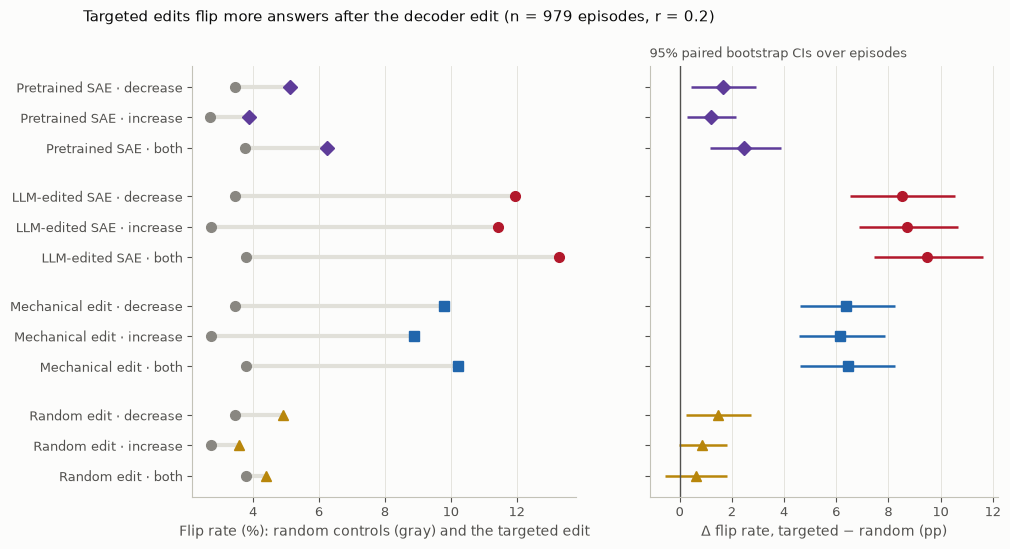

targeted %  random %         Δ (pp) [CI]  \
group           arm                                                  
Pretrained SAE  decrease         5.1       3.4   +1.7 [+0.4, +2.9]   
                increase         3.9       2.7   +1.2 [+0.3, +2.1]   
                both             6.2       3.7   +2.5 [+1.2, +3.9]   
LLM-edited SAE  decrease        12.0       3.4  +8.5 [+6.5, +10.6]   
                increase        11.4       2.7  +8.7 [+6.9, +10.7]   
                both            13.3       3.8  +9.5 [+7.5, +11.6]   
Mechanical edit decrease         9.8       3.4   +6.4 [+4.6, +8.2]   
                increase         8.9       2.7   +6.2 [+4.6, +7.9]   
                both            10.2       3.8   +6.4 [+4.6, +8.2]   
Random edit     decrease         4.9       3.4   +1.5 [+0.2, +2.7]   
                increase         3.6       2.7   +0.9 [-0.0, +1.8]   
                both             4.4       3.8   +0.6 [-0.5, +1.8]   

                          p (two-sided)  
group           arm                      
Pretrained SAE  decrease         0.0110  
                increase         0.0137  
                both             0.0005  
LLM-edited SAE  decrease         0.0001  
                increase         0.0001  
                both             0.0001  
Mechanical edit decrease         0.0001  
                increase         0.0001  
                both             0.0001  
Random edit     decrease         0.0264  
                increase         0.0900  
                both             0.3429

In [6]:
effect_rows = []
for group in GROUPS:
    for arm in ARMS:
        targeted = condition_values(group, arm, "targeted", is_flip)
        random = condition_values(group, arm, "random", is_flip)
        result = test(targeted, random)
        effect_rows.append({"group": group, "arm": arm, "targeted_pct": 100 * targeted.mean(),
                            "random_pct": 100 * random.mean(), "delta_pp": result["delta_pp"],
                            "ci_low_pp": result["ci95_pp"][0], "ci_high_pp": result["ci95_pp"][1],
                            "p_value": result["p_value"]})
effects = pd.DataFrame(effect_rows)


def row_positions() -> dict:
    return {(group, arm): i * (len(ARMS) + 0.6) + j for i, group in enumerate(GROUPS) for j, arm in enumerate(ARMS)}


fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.1, 1]})
positions = row_positions()
for (group, arm), y in positions.items():
    row = effects[(effects.group == group) & (effects.arm == arm)].iloc[0]
    color = GROUP_COLOR[group]
    axes[0].plot([row.random_pct, row.targeted_pct], [y, y], color=GRID, linewidth=3, zorder=1)
    axes[0].plot(row.random_pct, y, marker="o", color=RANDOM_GRAY, linestyle="none", zorder=2)
    axes[0].plot(row.targeted_pct, y, marker=GROUP_MARKER[group], color=color, linestyle="none", zorder=3)
    axes[1].plot([row.ci_low_pp, row.ci_high_pp], [y, y], color=color, linewidth=1.8, solid_capstyle="butt")
    axes[1].plot(row.delta_pp, y, marker=GROUP_MARKER[group], color=color, linestyle="none")
axes[0].set_yticks(list(positions.values()), [f"{group} · {arm}" for group, arm in positions])
axes[0].set_ylim(max(positions.values()) + 0.7, -0.7)
axes[0].set_xlabel("Flip rate (%): random controls (gray) and the targeted edit")
axes[1].axvline(0, color=INK_2, linewidth=1)
axes[1].set_xlabel("Δ flip rate, targeted − random (pp)")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Targeted edits flip more answers after the decoder edit (n = {len(COMMON)} episodes, r = {EDIT_SIZE})",
             x=0.02, ha="left", color=INK, fontsize=11)
axes[1].set_title("95% paired bootstrap CIs over episodes", loc="left", fontsize=9, color=INK_2)
save_figure(fig, "section1_flip_rates_and_delta")
plt.show()

display(pd.DataFrame({
    "targeted %": effects.targeted_pct.round(1).to_numpy(), "random %": effects.random_pct.round(1).to_numpy(),
    "Δ (pp) [CI]": [ci_cell(*v) for v in effects[["delta_pp", "ci_low_pp", "ci_high_pp"]].to_numpy()],
    "p (two-sided)": effects.p_value.round(4).to_numpy(),
}, index=pd.MultiIndex.from_frame(effects[["group", "arm"]])))

**Takeaway:** the edits make the targeted directions steer far harder, and only the targeted rate moves: all four
SAEs share the same random controls (2.7–3.8% flips). Δ rises from +1.2 to +2.5 pp (Pretrained) to +6.2 to +6.4
(mechanical) and +8.5 to +9.5 (LLM), in every arm. The random edit stays at the Pretrained SAE's level (+0.6 to
+1.5), so rotating these rows by 17° in arbitrary directions doesn't do it.

## 2. Paired contrasts

Per episode, one SAE's Δ minus another's, on the common episodes (two-sided). LLM vs Pretrained pairs rows across
the two runs; the others are within the new run. The sensitivity column repeats each contrast with the 4
differently-labeled random rows given the study's labels.

In [7]:
# The new run's rows with the study's labels on the 4 random rows that differ (sensitivity only).
relabel = {(d["group"], d["episode"], d["arm"], d["answer"]): d["study label"]
           for d in label_differences.to_dict("records")}
harmonized_rows = [{**r, "label": relabel.get((r["representation"], r["episode_id"], r["arm"], r["answer"]), r["label"])}
                   if r["kind"] == "edit" and r["source"] == "random" else r for r in new.rows]
harmonized = Outcomes(harmonized_rows, EDIT_SIZE, 3, new.plan)

CONTRASTS = [("LLM-edited SAE", PRETRAINED), ("LLM-edited SAE", "Mechanical edit"), ("LLM-edited SAE", "Random edit"),
             ("Mechanical edit", PRETRAINED), ("Mechanical edit", "Random edit")]
contrast_rows = []
for a, b in CONTRASTS:
    for arm in ARMS:
        result = test(per_episode_delta(a, arm), per_episode_delta(b, arm))
        alternative = {g: (harmonized if g in NEW_GROUPS else None) for g in (a, b)}
        sensitivity = test(per_episode_delta(a, arm, outcomes=alternative[a]),
                           per_episode_delta(b, arm, outcomes=alternative[b]))
        contrast_rows.append({"contrast": f"{a} vs {b}", "arm": arm,
                              "Δ_A − Δ_B (pp) [CI]": ci_cell(result["delta_pp"], *result["ci95_pp"]),
                              "p (two-sided)": round(result["p_value"], 4),
                              "with the study's 4 labels": ci_cell(sensitivity["delta_pp"], *sensitivity["ci95_pp"])})
contrasts = pd.DataFrame(contrast_rows).set_index(["contrast", "arm"])
display(contrasts)

Δ_A − Δ_B (pp) [CI]  p (two-sided)  \
contrast                          arm                                           
LLM-edited SAE vs Pretrained SAE  decrease   +6.8 [+4.8, +8.9]         0.0001   
                                  increase   +7.5 [+5.7, +9.5]         0.0001   
                                  both       +7.0 [+5.0, +9.1]         0.0001   
LLM-edited SAE vs Mechanical edit decrease   +2.1 [+0.6, +3.7]         0.0089   
                                  increase   +2.6 [+1.4, +3.8]         0.0001   
                                  both       +3.1 [+1.6, +4.5]         0.0002   
LLM-edited SAE vs Random edit     decrease   +7.0 [+5.0, +9.2]         0.0001   
                                  increase   +7.9 [+5.9, +9.9]         0.0001   
                                  both      +8.9 [+6.7, +11.0]         0.0001   
Mechanical edit vs Pretrained SAE decrease   +4.7 [+2.9, +6.6]         0.0001   
                                  increase   +5.0 [+3.4, +6.6]         0.0001   
                                  both       +3.9 [+2.1, +5.8]         0.0001   
Mechanical edit vs Random edit    decrease   +4.9 [+3.0, +6.8]         0.0001   
                                  increase   +5.3 [+3.6, +7.2]         0.0001   
                                  both       +5.8 [+3.9, +7.8]         0.0001   

                                           with the study's 4 labels  
contrast                          arm                                 
LLM-edited SAE vs Pretrained SAE  decrease         +6.8 [+4.8, +8.9]  
                                  increase         +7.6 [+5.7, +9.5]  
                                  both             +7.0 [+5.0, +9.1]  
LLM-edited SAE vs Mechanical edit decrease         +2.1 [+0.6, +3.7]  
                                  increase         +2.6 [+1.4, +3.8]  
                                  both             +3.1 [+1.6, +4.5]  
LLM-edited SAE vs Random edit     decrease         +7.0 [+5.0, +9.2]  
                                  increase         +7.9 [+5.9, +9.9]  
                                  both            +8.9 [+6.7, +11.0]  
Mechanical edit vs Pretrained SAE decrease         +4.7 [+2.9, +6.6]  
                                  increase         +5.0 [+3.4, +6.6]  
                                  both             +4.0 [+2.1, +5.8]  
Mechanical edit vs Random edit    decrease         +4.9 [+3.0, +6.8]  
                                  increase         +5.3 [+3.6, +7.2]  
                                  both             +5.8 [+3.9, +7.8]

**Takeaway:** the LLM edit beats the mechanical edit in all three arms, by +2.1 to +3.1 pp (p ≤ 0.009), and
both beat the Pretrained SAE and the random edit by wide margins. The 4 differently-labeled rows move no
contrast by more than 0.1 pp. (The held-out `steer_test` in section 4 pointed the same way, 36 vs 29 flips, but
with 400 episodes and one arm it couldn't separate them: p = 0.21.)

## 3. Better aimed, or just a bigger push?

An edit can raise flips by derailing the Solver: more answers that are neither candidate ("out"). For each targeted
edit: the share of answers that changed at all, the share that went out, and the share that flipped. If two edits
flip the same share of their **changed** answers, the difference between them is mostly how hard they push.

changed %  out %  random out %  flip %  \
group           arm                                                
Pretrained SAE  decrease      11.85   2.76          0.68    5.11   
                increase       5.11   0.00          0.37    3.88   
                both           8.27   0.51          0.78    6.23   
LLM-edited SAE  decrease      29.11  10.93          0.72   11.95   
                increase      21.96   7.05          0.34   11.44   
                both          30.85  11.95          0.78   13.28   
Mechanical edit decrease      25.64   7.46          0.72    9.81   
                increase      13.59   2.45          0.34    8.89   
                both          23.70   7.25          0.78   10.21   
Random edit     decrease      10.42   1.43          0.72    4.90   
                increase       4.90   0.20          0.34    3.58   
                both           7.05   0.72          0.78    4.39   

                          flips per changed answer  
group           arm                                 
Pretrained SAE  decrease                      0.43  
                increase                      0.76  
                both                          0.75  
LLM-edited SAE  decrease                      0.41  
                increase                      0.52  
                both                          0.43  
Mechanical edit decrease                      0.38  
                increase                      0.65  
                both                          0.43  
Random edit     decrease                      0.47  
                increase                      0.73  
                both                          0.62

out % difference (pp) [CI]  \
contrast                          arm                                   
LLM-edited SAE vs Mechanical edit decrease          +3.5 [+2.0, +5.0]   
                                  increase          +4.6 [+3.3, +6.0]   
                                  both              +4.7 [+3.2, +6.3]   
LLM-edited SAE vs Pretrained SAE  decrease         +8.2 [+6.1, +10.3]   
                                  increase          +7.0 [+5.5, +8.7]   
                                  both            +11.4 [+9.4, +13.6]   

                                            p (two-sided)  
contrast                          arm                      
LLM-edited SAE vs Mechanical edit decrease         0.0001  
                                  increase         0.0001  
                                  both             0.0001  
LLM-edited SAE vs Pretrained SAE  decrease         0.0001  
                                  increase         0.0001  
                                  both             0.0001

Saved results/intervention_llm_edited_layer25/20261112T005617641082Z-f48aae4eb4fa/merge/figures/llm_edit_analysis/section3_flips_vs_out.svg


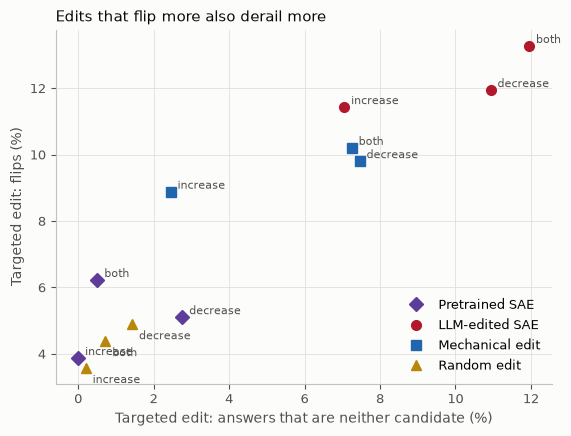

In [8]:
# Both runs replay the same baseline (prepare checked it against the stored answers), so either run's will do.
baseline_answer = {e: new.outcomes.rows[(e, "baseline")]["answer"] for e in COMMON}
assert all(study.outcomes.rows[(e, "baseline")]["answer"] == baseline_answer[e] for e in COMMON)


def changed(row: dict) -> bool:
    return row["answer"] != baseline_answer[row["episode_id"]]


aim_rows = []
for group in GROUPS:
    for arm in ARMS:
        values = {name: condition_values(group, arm, "targeted", value)
                  for name, value in (("changed", changed), ("out", is_out), ("flip", is_flip))}
        random_out = condition_values(group, arm, "random", is_out)
        aim_rows.append({"group": group, "arm": arm, "changed %": 100 * values["changed"].mean(),
                         "out %": 100 * values["out"].mean(), "random out %": 100 * random_out.mean(),
                         "flip %": 100 * values["flip"].mean(),
                         "flips per changed answer": values["flip"].sum() / max(values["changed"].sum(), 1)})
aim = pd.DataFrame(aim_rows).set_index(["group", "arm"]).round(2)
display(aim)

out_contrasts = []
for a, b in [("LLM-edited SAE", "Mechanical edit"), ("LLM-edited SAE", PRETRAINED)]:
    for arm in ARMS:
        result = test(condition_values(a, arm, "targeted", is_out), condition_values(b, arm, "targeted", is_out))
        out_contrasts.append({"contrast": f"{a} vs {b}", "arm": arm,
                              "out % difference (pp) [CI]": ci_cell(result["delta_pp"], *result["ci95_pp"]),
                              "p (two-sided)": round(result["p_value"], 4)})
display(pd.DataFrame(out_contrasts).set_index(["contrast", "arm"]))

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for group in GROUPS:
    rows = aim.loc[group]
    ax.plot(rows["out %"], rows["flip %"], marker=GROUP_MARKER[group], color=GROUP_COLOR[group], linestyle="none",
            label=group)
    for arm, row in rows.iterrows():
        ax.annotate(arm, (row["out %"], row["flip %"]), xytext=(5, -11 if group == "Random edit" else 2), textcoords="offset points", fontsize=8,
                    color=INK_2)
ax.grid(axis="y", visible=True)
ax.set_xlabel("Targeted edit: answers that are neither candidate (%)")
ax.set_ylabel("Targeted edit: flips (%)")
ax.set_title("Edits that flip more also derail more", loc="left")
ax.legend(loc="lower right")
save_figure(fig, "section3_flips_vs_out")
plt.show()

**What the out answers are:** the most common ones under each targeted "both" edit.

In [9]:
common_set = set(COMMON)
out_answers = {}
for group in GROUPS:
    key = Condition("edit", group, "both", "targeted", None, EDIT_SIZE).key
    answers = pd.Series([row["answer"] for (e, condition), row in OUTCOMES[group].rows.items()
                         if condition == key and e in common_set and is_out(row)])
    out_answers[f"{group} (n = {len(answers)})"] = [f"{answer!r} × {count}" for answer, count
                                                     in answers.value_counts().head(5).items()]
display(pd.DataFrame(dict((name, values + [""] * (5 - len(values))) for name, values in out_answers.items())))

,Pretrained SAE (n = 5),LLM-edited SAE (n = 117),Mechanical edit (n = 71),Random edit (n = 7)
0,'Insufficient evidence' × 1,'The evidence is insufficient.' × 86,'The evidence is insufficient.' × 62,'Kestrel Dam: Kestrel Dam is a concrete gravit...
1,'None of the provided paragraphs contain the i...,'19' × 5,'The Royal Conservatory of Music' × 1,'Insufficient evidence' × 1
2,'Lantern Hill Studios' × 1,'15' × 2,'The Temarin IV is manufactured by Ostrava Aer...,'Basel' × 1
3,'Osune River' × 1,'18' × 2,'The Shipping News' × 1,'None of the provided paragraphs contain the a...
4,'The Nessbourne River' × 1,'Kuopio' × 1,'The Wayback Machine is a digital archive of t...,'The evidence is insufficient.' × 1


**Takeaway: a bigger push, not a better aim.** The LLM edit changes 22–31% of answers, against 14–26% for
the mechanical edit and 5–12% for the Pretrained SAE, and it sends 7–12% of answers out, against 2–7% (mechanical)
and 0–3% (Pretrained). Its out-rate lead over the mechanical edit (+3.5 to +4.7 pp) is larger than its flip lead
(+2.1 to +3.1), and per changed answer it flips no more often (0.41–0.52, mechanical 0.38–0.65). Nearly all of
the out answers are one abstention, "The evidence is insufficient." (86 of 117 for the LLM "both" edit, 62 of 71
for mechanical): both edits push partly toward refusing, which fits Claude's own note that its behavior axis is
0.92-aligned with the "critic refuses / unanswerable" axis.

## 4. Before stage 6: the held-out `steer_test` and the audit

**Held out.** The same "both"-arm test Claude used, on 400 later train episodes it never saw (exact-match flips, no
labeler), for all three edits and the unedited SAE.

In [10]:
heldout = json.loads(Path(HELDOUT).read_text())
HELDOUT_NAMES = {"unedited": PRETRAINED, "llm": "LLM-edited SAE", "mechanical": "Mechanical edit", "random": "Random edit"}
first = next(iter(heldout["steer_test"].values()))
heldout_table = pd.DataFrame(
    [{"SAE": PRETRAINED, **first["unedited"]}]
    + [{"SAE": HELDOUT_NAMES[name], **summary["edited"]} for name, summary in heldout["steer_test"].items()]
).set_index("SAE")[["flips", "adoption_to_retention", "retention_to_adoption", "unclear", "mean_margin_change"]]
print(f"Episodes {heldout['episodes']['first']}..{heldout['episodes']['first'] + heldout['episodes']['count'] - 1}; "
      f"baseline reproduces the stored answer on {first['baseline_reproduces_stored_a2']} of {first['episodes']}.")
display(heldout_table.rename(columns={"unclear": "neither candidate", "mean_margin_change": "margin change"}).round(2))
paired = pd.DataFrame(heldout["paired_flips"]).T
paired.index = [" vs ".join(HELDOUT_NAMES[name] for name in pair.split(" vs ")) for pair in paired.index]
display(paired.astype({"only_first": int, "only_second": int, "both": int}).round({"p_value": 4}).rename(
    columns={"only_first": "flipped only under first", "only_second": "only under second",
             "both": "under both", "p_value": "exact McNemar p"}))

Episodes 200..599; baseline reproduces the stored answer on 400 of 400.


,flips,adoption_to_retention,retention_to_adoption,neither candidate,margin change
SAE,,,,,
Pretrained SAE,13,8,5,27,-1.52
LLM-edited SAE,36,23,13,93,3.77
Mechanical edit,29,20,9,63,2.64
Random edit,10,4,6,28,-1.47


,flipped only under first,only under second,under both,exact McNemar p
Pretrained SAE vs LLM-edited SAE,6,29,7,0.0001
Pretrained SAE vs Mechanical edit,6,22,7,0.0037
Pretrained SAE vs Random edit,5,2,8,0.4531
LLM-edited SAE vs Mechanical edit,15,8,21,0.2100
LLM-edited SAE vs Random edit,31,5,5,0.0000
Mechanical edit vs Random edit,25,6,4,0.0009


**Audit (Phase 5).** Every edited SAE replays from its `edits.py` to the saved file's hash, only the 20 selected
rows changed, and every edit kept its length and cosine ≥ 0.95 with the original row. The set directions moved as
below (`d` is the train mean-difference direction, host-only: Claude never saw it).

In [11]:
audit = json.loads(Path(AUDIT).read_text())
for name, group in audit["groups"].items():
    if not (group["params_sha256"]["match"] and group["only_selected_rows_changed"] and not group["rule_problems"]):
        raise AssertionError(f"The audit failed for {name}.")
display(pd.DataFrame([{"edit": name, "arm": arm, "cosine with original direction": s["cosine_with_original"],
                       "cosine with d": s["cosine_with_d"], "before the edit": s["original_cosine_with_d"]}
                      for name, group in audit["groups"].items() for arm, s in group["set_directions"].items()]
                     ).set_index(["edit", "arm"]).round(3))

cosine with original direction  cosine with d  \
edit       arm                                                        
llm        adoption                            0.478          0.582   
           retention                           0.471          0.855   
           both                                0.376          0.761   
mechanical adoption                            0.693          0.687   
           retention                           0.789          0.875   
           both                                0.692          0.877   
random     adoption                            0.956         -0.049   
           retention                           0.947          0.408   
           both                                0.946          0.269   

                      before the edit  
edit       arm                         
llm        adoption            -0.045  
           retention            0.432  
           both                 0.293  
mechanical adoption            -0.045  
           retention            0.432  
           both                 0.293  
random     adoption            -0.045  
           retention            0.432  
           both                 0.293

## 5. What Claude did

Claude's 24 snippets, one line each (its first sentence before the snippet), then its accepted edits and
its own summary. Edits happened in only 3 snippets, each setting all 20 rows at once; there was no edit-and-measure
search loop (audit).

In [12]:
run_record = json.loads((Path(LLM_RUN) / "run.json").read_text())
with open(Path(LLM_RUN) / "transcript.jsonl") as f:
    transcript = [json.loads(line) for line in f]


def what_it_did(prose: str, code_text: str) -> str:
    """Claude's first sentence before the snippet; failing that, the snippet's first comment or non-import line."""
    sentence = re.split(r"(?<=[.!?])\s", prose.strip(), maxsplit=1)[0] if prose.strip() else ""
    lines = [line.strip() for line in code_text.splitlines() if line.strip()]
    comments = [line.lstrip("# ").strip() for line in lines if line.startswith("#")]
    code_lines = [line for line in lines if not line.startswith(("#", "import ", "from "))]
    return (sentence or (comments or code_lines or [""])[0])[:120]


steps, prose = [], ""
for entry in transcript:
    if entry["kind"] == "assistant":
        text = " ".join(block["text"] for block in entry["content"] if block["type"] == "text")
        prose = re.sub(r"```.*?```", "", text, flags=re.S)
    elif entry["kind"] == "snippet":
        steps.append({"step": f"snippet {entry['number']}", "what": what_it_did(prose, entry["code"]),
                      "edits accepted": len(entry["accepted_edits"]), "error": "yes" if entry["error"] else ""})
    elif entry["kind"] == "steer_test":
        edited = entry["summary"]["edited"]
        steps.append({"step": f"steer_test {entry['number']}",
                      "what": f"{edited['flips']} flips, {edited['unclear']} neither candidate, "
                              f"margin {edited['mean_margin_change']:+.2f} (after {entry['edits_so_far']} edits)",
                      "edits accepted": 0, "error": ""})
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(steps).set_index("step"))
print(f"{run_record['turns']} turns, ${run_record['cost_usd_at_list_price']:.2f} at list price, "
      f"ended by {run_record['outcome']['ended_by']}.")

,what,edits accepted,error
step,,,
snippet 1,"Let me start by looking at what I have: the selected features, their hints, and the basic geometry of the two set di...",0,
snippet 2,"Now let me inspect the data: `meta_train` fields, activation scale, and the current geometry of `u_A`, `u_R`.",0,
snippet 3,"per-source difference of means, then average (removes source confound)",0,
snippet 4,split-half stability of d (per-source balanced),0,
snippet 5,"`d` is 0.67-aligned with the mean activation direction — that's a generic ""amplify everything"" axis, risky to steer ...",0,
snippet 6,`d_perp` (behavior direction orthogonal to the dominant mean-activation axis) separates classes slightly better than...,0,
snippet 7,"Before spending a steer_test call, let me check whether this direction is a behavior axis or a content confound: I'l...",0,
snippet 8,The stratified direction is 0.94-aligned with `d_perp` — some content confound.,0,yes
snippet 9,"No repeated questions, so no paired estimate.",0,


28 turns, $6.45 at list price, ended by DONE.


In [13]:
edits_source = (Path(LLM_RUN) / "edits.py").read_text()
rounds = {}
for number, feature, why in re.findall(r"    # edit (\d+), feature (\d+):\n((?:    #   .*\n)*)", edits_source):
    reason = " ".join(line.strip()[2:].strip() for line in why.splitlines())
    rounds.setdefault(reason, []).append(int(number))
display(Markdown("**`edits.py`** (" + f"{edits_source.count('row_sha256')} edits; each row is in `rows/`, checked by "
                 "sha256). The distinct reasons, by edit number:\n\n"
                 + "\n".join(f"- **Edits {min(n)}–{max(n)}:** {reason}" for reason, n in rounds.items())))
display(Markdown("**Claude's summary** (its DONE message, verbatim):\n\n" + run_record["claude_summary"]))

**`edits.py`** (60 edits; each row is in `rows/`, checked by sha256). The distinct reasons, by edit number:

- **Edits 1–10:** rotate 17.3 deg toward normalize(behavior_axis - u_A): behavior_axis is the train class- mean difference (adopt-retain, mean-activation axis removed), equal mix of the axis shared by musique/refusal cells and the axis of the majority synthetic-noref cell; the -u_A term cancels the set's old non-behavior direction coherently, so u_A-u_R aligns 0.96 with the behavior axis.
- **Edits 11–20:** rotate 17.3 deg toward normalize(-behavior_axis - u_R): behavior_axis is the train class- mean difference (adopt-retain, mean-activation axis removed), equal mix of the axis shared by musique/refusal cells and the axis of the majority synthetic-noref cell; the -u_A term cancels the set's old non-behavior direction coherently, so u_A-u_R aligns 0.96 with the behavior axis.
- **Edits 21–40:** dial the same edit down: each row rotated only 9.2 deg toward +/-behavior_axis (same axis as before: train class-mean difference adopt-retain, mean-activation axis removed, equal mix of the small-cell axis and the majority-cell axis). The steering direction is then 0.67*behavior_axis + 0.81*original direction; the original direction is near-inert (baseline margin -1.1), so this gives ~70% of the behavior push and should derail fewer generations into third answers.
- **Edits 41–60:** restore full-strength edit: each row rotated 17.3 deg (cos 0.955) toward normalize(+/-behavior_axis - u_set). behavior_axis = train class-mean difference (adoption-retention) with the mean-activation axis removed, as an equal mix of two near- orthogonal measured axes: the axis shared by the musique and critic-refusal cells and the axis of the majority synthetic/non-refusal cell. The -u_set term coherently cancels each set's old (non-behavior) direction, so normalize(u_A-u_R) has cosine 0.959 with the behavior axis instead of 0.11. Test showed 70% strength halves the effect, so strength is kept maximal.

**Claude's summary** (its DONE message, verbatim):

DONE

## What I did

**The lever.** The test's perturbation is `x' = x + 0.2·|x|·u` with `u` unit-norm, so *only the direction* of `normalize(u_A − u_R)` matters. My whole edit is aimed at pointing that one direction at a behavior axis measured in the train activations.

**Finding the axis (measurements only, no fitting).**
- The raw class-mean difference `mean(X|adopt) − mean(X|retain)` is 0.67-aligned with the mean-activation direction. A push along that axis mostly rescales the residual stream and is largely undone by downstream LayerNorm, so I projected the mean-activation axis out. The remainder separated classes slightly *better* (0.35/−0.41 sd in musique).
- Stratifying by (source × critic-refusal × numeric-answer) barely changed it (cos 0.94), so it is not a source artifact — but it *is* 0.92-aligned with the "critic refuses / question unanswerable" axis.
- Per-cell estimates revealed the important structure: the musique and refusal cells (44% of episodes) share one axis `t2` (gaps 0.5–1.8 sd), while the majority synthetic/non-refusal cell (56%) has a **near-orthogonal** axis `t6` (cos 0.13), on which `t2` is nearly useless (0.05 sd). Split-half checks: `t2` stable at cos 0.996, `t6` at 0.91 with honest OOS gap 0.274. Projecting onto top principal subspaces did not improve either, so I used raw estimates.
- Target = `normalize(t2 + t6)`, equal weight: because the axes are near-orthogonal, each keeps ~0.75 projection, so this preserves `t2`'s strong separation in the small cells (1.66/0.44/1.72) *and* recovers the majority cell (0.05 → 0.32). Honest reweighting checks were flat between w=1.0 and 1.5, so I kept the simple equal mix.

**The edit.** Each of the 20 rows was rotated by exactly 17.3° (cos 0.955, length preserved) toward `normalize(±behavior_axis − u_set)`: the first term builds signal, the second cancels the set's old non-behavior direction *coherently across the 10 rows* (each row carries ~0.32 of `Ŝ`, and 10 rotations of 0.30 nearly erase a sum of norm 3.2). That two-term choice, with equal weight β=1, raised `cos(normalize(u_A − u_R), behavior_axis)` from **0.11 to 0.959** — 96% of the theoretical maximum — whereas rotating toward the axis alone gave only 0.856.

**One thing I tested and rejected.** At full strength, "answers matching neither" rose 14 → 47, so I tried a 70%-strength variant (9.2° rotation, remainder carried by the original, empirically near-inert direction). Derailment fell 47 → 24 but flips fell 24 → 14 and the margin +4.91 → +1.32: over-steering was *not* the binding constraint, the response is steeply monotone in push strength. I restored full strength and verified the host state is bit-identical to the measured configuration.

## Result and expectation

Confirmed on the 200 train episodes: **24 flips vs 13 unedited**, improved in both directions (adopted→retains 15 vs 10; retained→adopts 9 vs 3), with mean candidate-margin change **+4.91 vs −1.12**.

I expect this to transfer, since the axis came from 25k episodes with split-half cos ≥ 0.91 and is not a source confound. The margin gain (+6 nats swing) should be the most reliable part; flip counts will be noisy. The main residual weakness is that ~24% of episodes now answer something matching neither candidate — plausibly refusals, since the axis is substantially the "unanswerable" axis; a cleaner refusal-stripped axis exists but loses almost all separation in the refusal cells (1.66 → 0.10 sd), so I judged it a worse trade.

## 6. What we can and can't say

**What we can say (exploratory, train-label-guided)**
- Re-aiming 20 decoder rows (about 51k of the SAE's 84M parameters) within a cosine-0.95 cap makes the same features
  steer 3–5× harder in stage 6: Δ from about +2 pp to +6 (formula) or +9 (Claude). The encoder, the selected features
  and the random controls are unchanged, so this is purely a better steering direction.
- Claude's edit beats the formula's on flips in every arm (+2.1 to +3.1 pp), out of sample (stage-6 episodes are
  never train), with the random controls reproducing the study's token for token.
- A random rotation of the same per-row size does nothing.

**What we can't say**
- **That Claude found a better-aimed direction.** Its extra flips come with more extra derailment (mostly "The
  evidence is insufficient."), and it flips no more per changed answer. A strength-matched comparison is needed:
  e.g. scale each edit down to the same out rate, as Claude's own 70% trial did (14 flips, 24 neither, on train).
- **That the random edit is a strong control.** It matches each row's angle, but its 10 random rotations mostly
  cancel, so the steering direction barely moves (cosine 0.95 with the original, vs 0.38 for Claude's). A
  "coherent random" edit, all rows toward one random direction, would test "any large move of the set direction".
- **That the comparison is even-handed.** Claude also saw `steer_test` results on 200 train episodes; the formula
  saw nothing but the labels.
- **Anything confirmatory.** One run, one LLM sample, one layer, one r; nothing here was pre-registered.

**Next:** read a sample of LLM-edit flips and out answers by hand; a strength-matched comparison and a coherent
random edit if this goes in the paper.